In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import geodatasets
import os


def plot_hurricane(base_path):
    """
    Plot a hurricane track, wind swath, and wind radii.

    Parameters
    ----------
    base_path : str
        Path to the hurricane best-track folder.

        Example:
            "data/al092024_best_track"

    Expected files inside the folder:
        AL092024_lin.shp
        AL092024_pts.shp
        AL092024_radii.shp
        AL092024_windswath.shp
    """

    # ==================================================
    # GET HURRICANE ID FROM FOLDER NAME
    # ==================================================

    folder_name = os.path.basename(os.path.normpath(base_path))

    # Example:
    # al092024_best_track -> al092024
    storm_id = folder_name.replace("_best_track", "").upper()

    # ==================================================
    # LOAD DATA
    # ==================================================

    track_line = gpd.read_file(
        f"{base_path}/{storm_id}_lin.shp"
    )

    track_points = gpd.read_file(
        f"{base_path}/{storm_id}_pts.shp"
    )

    wind_radii = gpd.read_file(
        f"{base_path}/{storm_id}_radii.shp"
    )

    wind_swath = gpd.read_file(
        f"{base_path}/{storm_id}_windswath.shp"
    )

    # ==================================================
    # LOAD WORLD MAP
    # ==================================================

    world = gpd.read_file(
        geodatasets.get_path("naturalearth.land")
    )

    world = world.to_crs(track_line.crs)

    # ==================================================
    # MAP EXTENT
    # ==================================================

    xmin, xmax = -110, -20
    ymin, ymax = 5, 60

    world_region = world.cx[xmin:xmax, ymin:ymax]

    # ==================================================
    # FIGURE
    # ==================================================

    fig, ax = plt.subplots(figsize=(15, 10))

    # Ocean
    ax.set_facecolor("#d9eef7")

    # ==================================================
    # LAND
    # ==================================================

    world_region.plot(
        ax=ax,
        color="#eeeeee",
        edgecolor="#777777",
        linewidth=0.6,
        zorder=1
    )

    # ==================================================
    # WIND SWATH
    # ==================================================

    wind_swath.plot(
        ax=ax,
        color="#4da6ff",
        alpha=0.18,
        edgecolor="none",
        zorder=2
    )

    # ==================================================
    # WIND RADII
    # ==================================================

    wind_radii.plot(
        ax=ax,
        color="#ffd166",
        alpha=0.12,
        edgecolor="#e6a800",
        linewidth=0.5,
        zorder=3
    )

    # ==================================================
    # HURRICANE PATH
    # ==================================================

    # Outer glow / halo
    track_line.plot(
        ax=ax,
        color="black",
        linewidth=7,
        alpha=0.35,
        zorder=4
    )

    # Main track
    track_line.plot(
        ax=ax,
        color="#e63946",
        linewidth=4,
        zorder=5
    )

    # ==================================================
    # TRACK POINTS
    # ==================================================

    x = track_points.geometry.x.values
    y = track_points.geometry.y.values

    # Progress through storm
    progress = np.linspace(0, 1, len(track_points))

    ax.scatter(
        x,
        y,
        c=progress,
        cmap="plasma",
        s=80,
        edgecolor="white",
        linewidth=1.5,
        zorder=6
    )

    # ==================================================
    # DIRECTION ARROWS
    # ==================================================

    step = max(1, len(x) // 10)

    for i in range(0, len(x) - 1, step):

        dx = x[i + 1] - x[i]
        dy = y[i + 1] - y[i]

        ax.annotate(
            "",
            xy=(
                x[i] + dx * 0.65,
                y[i] + dy * 0.65
            ),
            xytext=(x[i], y[i]),
            arrowprops=dict(
                arrowstyle="->",
                linewidth=2,
                color="#7f0000"
            ),
            zorder=7
        )

    # ==================================================
    # START / END MARKERS
    # ==================================================

    ax.scatter(
        x[0],
        y[0],
        s=180,
        color="white",
        edgecolor="green",
        linewidth=3,
        zorder=8
    )

    ax.scatter(
        x[-1],
        y[-1],
        s=180,
        color="white",
        edgecolor="black",
        linewidth=3,
        zorder=8
    )

    # ==================================================
    # START / END LABELS
    # ==================================================

    ax.text(
        x[0],
        y[0] + 1,
        "START",
        fontsize=10,
        fontweight="bold",
        ha="center",
        zorder=9
    )

    ax.text(
        x[-1],
        y[-1] + 1,
        "END",
        fontsize=10,
        fontweight="bold",
        ha="center",
        zorder=9
    )

    # ==================================================
    # MAP LIMITS
    # ==================================================

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    # ==================================================
    # GRID
    # ==================================================

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.5,
        alpha=0.35
    )

    ax.set_axisbelow(True)

    # ==================================================
    # TITLE
    # ==================================================

    ax.set_title(
        "Hurricane Track and Wind Field",
        fontsize=22,
        fontweight="bold",
        pad=20
    )

    ax.text(
        0.5,
        1.01,
        f"{storm_id} Best Track",
        transform=ax.transAxes,
        ha="center",
        fontsize=12,
        color="dimgray"
    )

    # ==================================================
    # AXES
    # ==================================================

    ax.set_xlabel(
        "Longitude",
        fontsize=12
    )

    ax.set_ylabel(
        "Latitude",
        fontsize=12
    )

    # ==================================================
    # LEGEND
    # ==================================================

    legend_elements = [
        Line2D(
            [0],
            [0],
            color="#e63946",
            linewidth=4,
            label="Hurricane Track"
        ),

        Line2D(
            [0],
            [0],
            marker="o",
            color="white",
            markerfacecolor="#e63946",
            markersize=8,
            linewidth=0,
            label="Track Positions"
        ),

        Patch(
            facecolor="#4da6ff",
            alpha=0.18,
            label="Wind Swath"
        ),

        Patch(
            facecolor="#ffd166",
            alpha=0.20,
            label="Wind Radii"
        ),

        Line2D(
            [0],
            [0],
            marker="o",
            color="white",
            markerfacecolor="white",
            markeredgecolor="green",
            markersize=9,
            linewidth=0,
            label="Start"
        )
    ]

    ax.legend(
        handles=legend_elements,
        loc="upper right",
        frameon=True,
        framealpha=0.95
    )

    # ==================================================
    # CLEAN FRAME
    # ==================================================

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

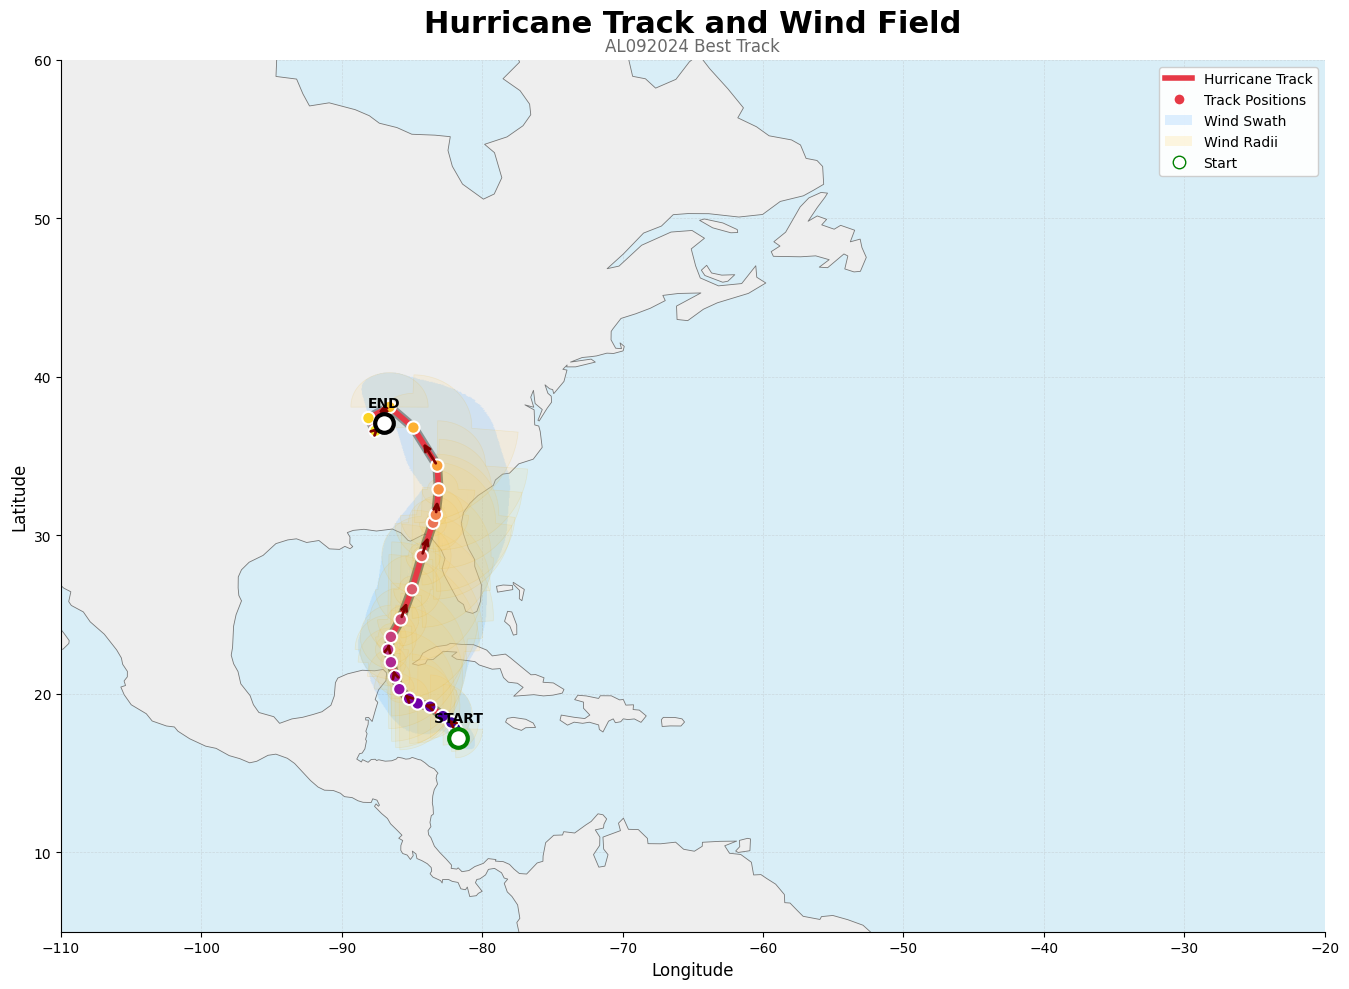

In [3]:
plot_hurricane("data/al092024_best_track")

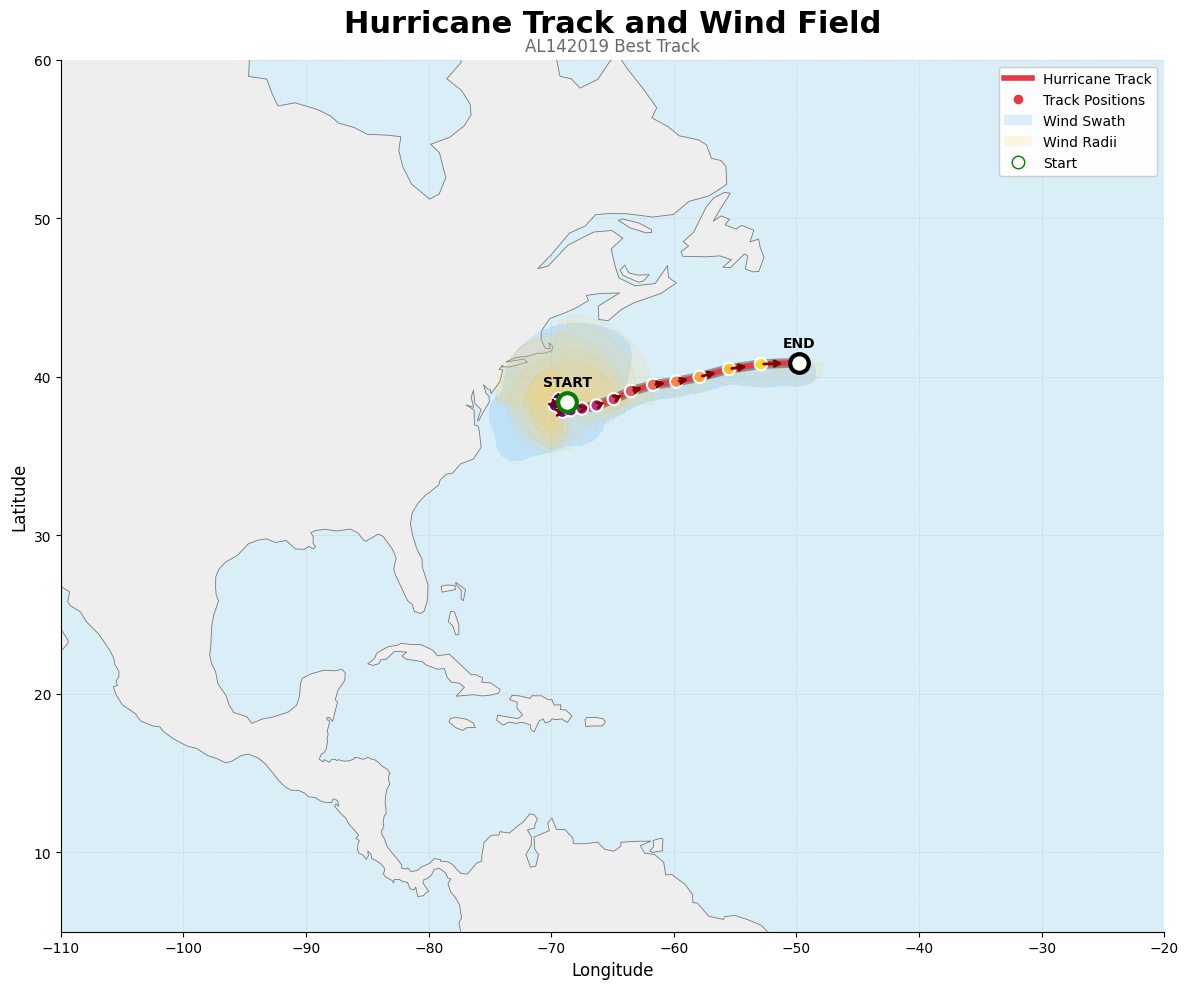

In [4]:
plot_hurricane("data/al142019_best_track")

In [9]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import geodatasets
import numpy as np
import pandas as pd
import os


def animate_hurricane(base_path, output_file=None, interval=500):
    """
    Create an actual animated GIF of a hurricane moving through time.

    Parameters
    ----------
    base_path : str
        Hurricane best-track folder.

        Example:
            "data/al092024_best_track"

    output_file : str, optional
        Name/path of the output GIF.

        Example:
            "AL092024_animation.gif"

        If None, automatically creates:
            AL092024_animation.gif

    interval : int
        Milliseconds between animation frames.
    """

    # ==================================================
    # IDENTIFY STORM
    # ==================================================

    folder_name = os.path.basename(
        os.path.normpath(base_path)
    )

    storm_id = folder_name.replace(
        "_best_track", ""
    ).upper()

    # ==================================================
    # FILES
    # ==================================================

    track_line_file = f"{base_path}/{storm_id}_lin.shp"
    track_points_file = f"{base_path}/{storm_id}_pts.shp"
    wind_radii_file = f"{base_path}/{storm_id}_radii.shp"
    wind_swath_file = f"{base_path}/{storm_id}_windswath.shp"

    # ==================================================
    # LOAD DATA
    # ==================================================

    track_line = gpd.read_file(track_line_file)

    track_points = gpd.read_file(track_points_file)

    wind_radii = gpd.read_file(wind_radii_file)

    wind_swath = gpd.read_file(wind_swath_file)

    # ==================================================
    # FIND TIME COLUMN
    # ==================================================

    possible_time_columns = [
        "DATE_TIME",
        "DATETIME",
        "DATE",
        "TIME",
        "VALID_TIME",
        "ISO_TIME",
        "TIME_UTC",
        "DTG",
    ]

    time_column = None

    for column in possible_time_columns:
        if column in track_points.columns:
            time_column = column
            break

    # Search more generally if needed
    if time_column is None:

        for column in track_points.columns:

            column_upper = column.upper()

            if (
                "DATE" in column_upper
                or "TIME" in column_upper
                or "DTG" in column_upper
            ):
                time_column = column
                break

    if time_column is None:

        print("Available columns:")
        print(track_points.columns.tolist())

        raise ValueError(
            "No timestamp column could be found."
        )

    print(
        f"Using timestamp column: {time_column}"
    )

    # ==================================================
    # CONVERT TO DATETIME
    # ==================================================

    track_points["timestamp"] = pd.to_datetime(
        track_points[time_column],
        errors="coerce"
    )

    # Remove invalid timestamps
    track_points = track_points.dropna(
        subset=["timestamp"]
    )

    # Sort chronologically
    track_points = track_points.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    # ==================================================
    # COORDINATES
    # ==================================================

    x = track_points.geometry.x.values
    y = track_points.geometry.y.values

    timestamps = track_points["timestamp"].values

    # ==================================================
    # WORLD MAP
    # ==================================================

    world = gpd.read_file(
        geodatasets.get_path("naturalearth.land")
    )

    world = world.to_crs(
        track_line.crs
    )

    # ==================================================
    # MAP EXTENT
    # ==================================================

    xmin, xmax = -110, -20
    ymin, ymax = 5, 60

    world_region = world.cx[
        xmin:xmax,
        ymin:ymax
    ]

    # ==================================================
    # FIGURE
    # ==================================================

    fig, ax = plt.subplots(
        figsize=(15, 10)
    )

    ax.set_facecolor(
        "#d9eef7"
    )

    # ==================================================
    # LAND
    # ==================================================

    world_region.plot(
        ax=ax,
        color="#eeeeee",
        edgecolor="#777777",
        linewidth=0.6,
        zorder=1
    )

    # ==================================================
    # WIND SWATH
    # ==================================================

    wind_swath.plot(
        ax=ax,
        color="#4da6ff",
        alpha=0.10,
        edgecolor="none",
        zorder=2
    )

    # ==================================================
    # WIND RADII
    # ==================================================

    wind_radii.plot(
        ax=ax,
        color="#ffd166",
        alpha=0.08,
        edgecolor="#e6a800",
        linewidth=0.5,
        zorder=3
    )

    # ==================================================
    # STATIC FULL TRACK
    # ==================================================

    track_line.plot(
        ax=ax,
        color="black",
        linewidth=7,
        alpha=0.12,
        zorder=4
    )

    track_line.plot(
        ax=ax,
        color="#e63946",
        linewidth=3,
        alpha=0.12,
        zorder=5
    )

    # ==================================================
    # ANIMATED TRACK
    # ==================================================

    animated_line, = ax.plot(
        [],
        [],
        color="#e63946",
        linewidth=4,
        zorder=6
    )

    # ==================================================
    # TRACK POINTS
    # ==================================================

    animated_points = ax.scatter(
        [],
        [],
        s=70,
        color="#e63946",
        edgecolor="white",
        linewidth=1.5,
        zorder=7
    )

    # ==================================================
    # CURRENT HURRICANE POSITION
    # ==================================================

    hurricane_marker = ax.scatter(
        [],
        [],
        s=240,
        color="white",
        edgecolor="black",
        linewidth=3,
        zorder=8
    )

    # ==================================================
    # START MARKER
    # ==================================================

    ax.scatter(
        x[0],
        y[0],
        s=180,
        color="white",
        edgecolor="green",
        linewidth=3,
        zorder=9
    )

    # ==================================================
    # TEXT
    # ==================================================

    title = ax.set_title(
        "",
        fontsize=22,
        fontweight="bold",
        pad=20
    )

    subtitle = ax.text(
        0.5,
        1.01,
        f"{storm_id} Best Track",
        transform=ax.transAxes,
        ha="center",
        fontsize=12,
        color="dimgray"
    )

    # ==================================================
    # AXES
    # ==================================================

    ax.set_xlim(
        xmin,
        xmax
    )

    ax.set_ylim(
        ymin,
        ymax
    )

    ax.set_xlabel(
        "Longitude",
        fontsize=12
    )

    ax.set_ylabel(
        "Latitude",
        fontsize=12
    )

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.5,
        alpha=0.35
    )

    ax.set_axisbelow(True)

    # ==================================================
    # UPDATE FRAME
    # ==================================================

    def update(frame):

        # Track up to current point
        animated_line.set_data(
            x[:frame + 1],
            y[:frame + 1]
        )

        # Points up to current point
        animated_points.set_offsets(
            np.column_stack(
                [
                    x[:frame + 1],
                    y[:frame + 1]
                ]
            )
        )

        # Current hurricane position
        hurricane_marker.set_offsets(
            [[
                x[frame],
                y[frame]
            ]]
        )

        # Current timestamp
        timestamp = pd.Timestamp(
            timestamps[frame]
        )

        title.set_text(
            f"Hurricane {storm_id} — "
            f"{timestamp.strftime('%B %d, %Y %H:%M UTC')}"
        )

        return (
            animated_line,
            animated_points,
            hurricane_marker,
            title
        )

    # ==================================================
    # CREATE ANIMATION
    # ==================================================

    animation = FuncAnimation(
        fig,
        update,
        frames=len(track_points),
        interval=interval,
        repeat=False,
        blit=False
    )

    # ==================================================
    # OUTPUT FILE
    # ==================================================

    if output_file is None:

        output_file = (
            f"{storm_id}_animation.gif"
        )

    print(
        f"Saving animation to: {output_file}"
    )

    animation.save(
        output_file,
        writer=PillowWriter(
            fps=1000 // interval
        )
    )

    print("Animation saved!")

    plt.close(fig)

    return output_file

In [10]:
animate_hurricane(
    "data/al092024_best_track"
)

Using timestamp column: DTG
Saving animation to: AL092024_animation.gif
Animation saved!


'AL092024_animation.gif'